# Models for the forecasting of cholera cases in Uvira

## Environment setup

In [36]:
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Time series feature engineering
from tsfresh.utilities.dataframe_functions import roll_time_series
from tsfresh import extract_features, select_features, extract_relevant_features
from tsfresh.utilities.dataframe_functions import impute

# Forecasting
from darts import TimeSeries
from darts.models import BlockRNNModel, RegressionModel
from darts.metrics import rmse

In [2]:
seed = sum(map(ord, "Forecasting model - Uvira")) 
rng = np.random.default_rng(seed = seed)

## Folder Structure

In [3]:
raw_data_dir = Path("../../data/raw")
processed_data_dir = Path("../../data/processed")
img_dir = Path("../../images")
img_dir.mkdir(exist_ok=True)

## Functions

In [24]:
def eval_model(
    model, 
    y,
    past_covariates=None, 
    future_covariates=None,
    test_size=0.2,
    forecast_horizon=4
):
    
    # We backtest the model on the last 20% of the flow series, with a horizon of 10 steps:
    backtest = model.historical_forecasts(
        series=y, 
        past_covariates=past_covariates,
        future_covariates=future_covariates,
        start=1-test_size, 
        retrain=False,
        verbose=True, 
        forecast_horizon=forecast_horizon
    )
    
    y[-len(backtest)-52:].plot()
    backtest.plot(label=f"backtest (n={forecast_horizon})")
    print(f"Backtest RMSE = {rmse(y, backtest)}")


# Aggregation functions
def na_sum(x):
    if all(x.isna()):
        return np.nan
    else:
        return x.dropna().sum()

def na_log_sum(x):
    if all(x.isna()):
        return np.nan
    else:
        tot = x.dropna().sum()
        if tot > 0:
            return np.log(tot + 1)
        elif tot == 0:
            return 0
        else:
            return -np.log(-tot + 1)

def na_mean(x):
    if all(x.isna()):
        return np.nan
    else:
        return x.dropna().mean()


def standardize(x):
    return (x - x.mean()) / x.std()


def normalize(x):
    return (x - x.min()) / (x.max() - x.min())


def mask_target(x):
    """
    this mask returns an array of 1s where the last entry is a 0.
    Used to mask the rolled time series to avoid using the target in the features.
    """
    result = np.ones(len(x))
    result[-1] = 0
    return result

## Import data

In [5]:
df = pd.read_csv(
    processed_data_dir / "uvira_full_data.csv",
    parse_dates=["date"]
)

## Parameters

In [6]:
START_DATE = "2016-05-01"
END_DATE = df["date"].max().strftime("%Y-%m-%d")
TIME_BIN = 7
FORECAST_HORIZON = int(30 / TIME_BIN)

## Aggregate Data

In [85]:
df_weekly = (
    df
    .groupby(pd.Grouper(key = "date", freq = f"{TIME_BIN}D"), dropna=True)
    .agg({
        "reports": na_sum,
        "vacc_1": na_sum,
        "vacc_2": na_sum,
        "rainfall_mm": na_sum,
        "esi": na_mean,
        "lake_level": na_mean,
        "num_fatalities": na_log_sum,
        "num_disaster_affected": na_log_sum,
        "idps": na_log_sum,
    })
    .loc[lambda x: (
        (x.index >= START_DATE)
        & (x.index < END_DATE)
    )]
    .reset_index()
    .rename(columns = {
        "date": "ds",
        "reports": "y"
    })
    .assign(
        unique_id = 1,
        week = lambda x: (0.5 * (1 + np.sin(2 * np.pi * (x["ds"].dt.isocalendar().week + 30) / 52))).astype(float),
        rainfall_mm = lambda x: standardize(x["rainfall_mm"]),
        esi = lambda x: standardize(x["esi"]),
        lake_level = lambda x: standardize(x["lake_level"]),
        num_fatalities = lambda x: normalize(x["num_fatalities"]),
        num_disaster_affected = lambda x: normalize(x["num_disaster_affected"]),
        idps = lambda x: normalize(x["idps"].fillna(0)),
        vacc = lambda x: normalize(x["vacc_1"] + x["vacc_2"]),
        rain_sum_4w = lambda x: standardize(sum([x["rainfall_mm"].shift(i) for i in range(5)])),
        rain_sum_8w = lambda x: standardize(sum([x["rainfall_mm"].shift(i) for i in range(9)])),
        esi_mean_4w = lambda x: standardize(sum([x["esi"].shift(i) for i in range(5)])/4),
        esi_mean_8w = lambda x: standardize(sum([x["esi"].shift(i) for i in range(9)])/8),
        lake_level_mean_4w = lambda x: standardize(sum([x["lake_level"].shift(i) for i in range(5)])/4),
        lake_level_mean_8w = lambda x: standardize(sum([x["lake_level"].shift(i) for i in range(9)])/8),
        num_fatalities_sum_4w = lambda x: normalize(sum([x["num_fatalities"].shift(i) for i in range(5)])),
        num_fatalities_sum_8w = lambda x: normalize(sum([x["num_fatalities"].shift(i) for i in range(9)])),
        num_disaster_affected_sum_4w = lambda x: normalize(sum([x["num_disaster_affected"].shift(i) for i in range(5)])),
        num_disaster_affected_sum_8w = lambda x: normalize(sum([x["num_disaster_affected"].shift(i) for i in range(9)])),
        idps_sum_4w = lambda x: normalize(sum([x["idps"].shift(i) for i in range(5)])),
        idps_sum_8w = lambda x: normalize(sum([x["idps"].shift(i) for i in range(9)])),
        **{
            f"rain_{i}w": lambda x: x["rainfall_mm"].shift(i) for i in range(1, 9)
        },
        **{
            f"esi_{i}w": lambda x: x["esi"].shift(i) for i in range(1, 9)
        },
        **{
            f"lake_level_{i}w": lambda x: x["lake_level"].shift(i) for i in range(1, 9)
        },
        **{
            f"num_fatalities_{i}w": lambda x: x["num_fatalities"].shift(i) for i in range(1, 9)
        },
        **{
            f"num_disaster_affected_{i}w": lambda x: x["num_disaster_affected"].shift(i) for i in range(1, 9)
        },
        **{
            f"idps_{i}w": lambda x: x["idps"].shift(i) for i in range(1, 9)
        },
        **{
            f"vacc_{i}w": lambda x: x["vacc"].shift(i) for i in range(1, 9)
        }
    )
    .drop(columns = ["vacc_1", "vacc_2"])
    .dropna()
    .reset_index(drop=True)
)



### Test date split

In [86]:
test_date_split = df_weekly["ds"].iloc[(
    df_weekly
    .loc[lambda x: x["ds"] > "2024-01-01"]
    .assign(
        thresh_cross = lambda x: x["y"] >= 15
    )
    ["thresh_cross"]
    .loc[lambda x: x == True]
    .index[0] + 1
)]

## Feature Engineering

### Create rolling datasets

Note that the rolling procedure includes the current timestamp so we need to drop the current value

In [87]:
lookback_period = 4
df_weekly_rolled = (
    roll_time_series(
        df_weekly.drop(columns=["y"]),
        column_id = "unique_id",
        column_sort = "ds",
        min_timeshift = lookback_period,
        max_timeshift = lookback_period
    )
    .drop(columns = ["unique_id"])
)

Rolling: 100%|██████████| 30/30 [00:03<00:00,  8.11it/s]


In [88]:
mask = (
    df_weekly_rolled
    .groupby("id")
    ["id"]
    .transform(mask_target)
    .astype(bool)
    .values
)

In [89]:
df_weekly_rolled_masked = (
    df_weekly_rolled
    .copy()
    [mask]
    .reset_index(drop = True)
)

### Build features

In [90]:
df_features = (
    extract_features(
        df_weekly_rolled_masked,
        column_id = "id",
        column_sort = "ds",
    )
    [lambda x: [c for c in x.columns if (x[c].isna().sum() == 0) & (x[c].std() > 0)]]
)

Feature Extraction: 100%|██████████| 30/30 [02:37<00:00,  5.24s/it]
/Users/paoich/miniforge3/envs/cholera-surveillance/lib/python3.12/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


In [91]:
df_ts_model_features = (
    impute(df_features)
    .apply(lambda x: normalize(x), axis = 0)
    .reset_index()
    .drop(columns = ["level_0"])
    .rename(columns = {"level_1": "ds"})
    .dropna(axis = 1)
)

In [92]:
df_ts_model_features.shape

(439, 11836)

## Data for model

In [ ]:
df_model = (
    df_weekly
    .assign(
        week = lambda x: 0.5 * (1 + np.sin(2 * np.pi * (x["ds"].dt.isocalendar().week + 30) / 52)),
        rain_sum_4w = lambda x: sum([x["rainfall_mm"].shift(i) for i in range(5)]),
        rain_sum_8w = lambda x: sum([x["rainfall_mm"].shift(i) for i in range(9)]),
        esi_mean_4w = lambda x: sum([x["esi"].shift(i) for i in range(5)])/4,
        esi_mean_8w = lambda x: sum([x["esi"].shift(i) for i in range(9)])/8,
        lake_level_mean_4w = lambda x: sum([x["lake_level"].shift(i) for i in range(5)])/4,
        lake_level_mean_8w = lambda x: sum([x["lake_level"].shift(i) for i in range(9)])/8,
        num_fatalities_sum_4w = lambda x: sum([x["num_fatalities"].shift(i) for i in range(5)]),
        num_fatalities_sum_8w = lambda x: sum([x["num_fatalities"].shift(i) for i in range(9)]),
        num_disaster_affected_sum_4w = lambda x: sum([x["num_disaster_affected"].shift(i) for i in range(5)]),
        num_disaster_affected_sum_8w = lambda x: sum([x["num_disaster_affected"].shift(i) for i in range(9)]),
        idps_sum_4w = lambda x: sum([x["idps"].shift(i) for i in range(5)]),
        idps_sum_8w = lambda x: sum([x["idps"].shift(i) for i in range(9)]),
        **{
            f"rain_{i}w": lambda x: x["rainfall_mm"].shift(i) for i in range(1, 9)
        },
        **{
            f"esi_{i}w": lambda x: x["esi"].shift(i) for i in range(1, 9)
        },
        **{
            f"lake_level_{i}w": lambda x: x["lake_level"].shift(i) for i in range(1, 9)
        },
        **{
            f"num_fatalities_{i}w": lambda x: x["num_fatalities"].shift(i) for i in range(1, 9)
        },
        **{
            f"num_disaster_affected_{i}w": lambda x: x["num_disaster_affected"].shift(i) for i in range(1, 9)
        },
        **{
            f"idps_{i}w": lambda x: x["idps"].shift(i) for i in range(1, 9)
        },
        **{
            f"vacc_{i}w": lambda x: x["vacc"].shift(i) for i in range(1, 9)
        }
    )
    # .drop(columns = [
    #     "rainfall_mm", 
    #     "esi",
    #     "lake_level",
    #     "num_fatalities",
    #     "num_disaster_affected",
    #     "idps",
    #     "vacc",
    #     "unique_id"
    # ])
    # .merge(
    #     df_ts_model_features,
    #     how = "left",
    #     on = "ds"
    # )
    .dropna()
    .reset_index(drop = True)
)
    

In [55]:
df_model.head()

,unique_id,ds,y,rainfall_mm,esi,lake_level,num_fatalities,num_disaster_affected,idps,vacc,...,esi_mean_4w,esi_mean_8w,lake_level_mean_4w,lake_level_mean_8w,num_fatalities_sum_4w,num_fatalities_sum_8w,num_disaster_affected_sum_4w,num_disaster_affected_sum_8w,idps_sum_4w,idps_sum_8w
0,1,2016-07-01,48,-1.183248,0.946551,-0.913696,0.000000,0.0,0.522575,0.0,...,0.946856,0.839699,-1.083082,-0.943836,0.000000,0.000000,0.0,0.0,2.612876,4.703176
1,1,2016-07-08,61,-1.176044,0.954973,-0.879587,0.000000,0.0,0.522575,0.0,...,1.062266,0.828806,-1.106299,-0.945161,0.000000,0.000000,0.0,0.0,2.612876,4.703176
2,1,2016-07-15,33,-1.209440,1.261804,-0.948821,0.000000,0.0,0.522575,0.0,...,1.233844,0.899553,-1.149777,-0.962097,0.000000,0.000000,0.0,0.0,2.612876,4.703176
3,1,2016-07-22,51,-1.176558,1.435027,-1.065029,0.164272,0.0,0.522575,0.0,...,1.400555,1.006276,-1.189517,-1.000487,0.164272,0.164272,0.0,0.0,2.612876,4.703176
4,1,2016-07-29,79,-1.193033,1.612975,-1.170578,0.000000,0.0,0.522575,0.0,...,1.552832,1.131526,-1.244428,-1.049543,0.164272,0.164272,0.0,0.0,2.612876,4.703176


In [17]:
OUTPUT_FILEDATE = pd.Timestamp("today").strftime("%Y%m%d")
(
    df_model
    .rename(
        columns = {
            "ds": "date",
            "y": "reports",
        }
    )
    .to_csv(processed_data_dir / f"uvira_forecast_data_{OUTPUT_FILEDATE}.csv", index=False)
)

## Train-validation-test split

In [56]:
df_train = df_model[df_model["ds"] < test_date_split].reset_index(drop=True)
df_test = df_model[df_model["ds"] >= test_date_split].reset_index(drop=True)

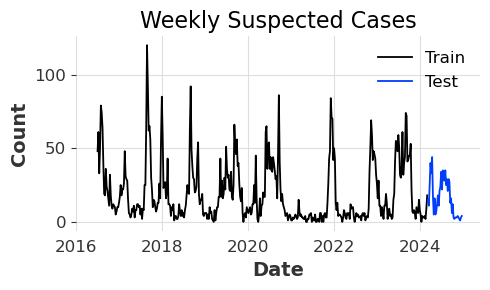

In [19]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(df_train["ds"], df_train["y"], label="Train")
ax.plot(df_test["ds"], df_test["y"], label="Test")
ax.legend(fontsize=12)
ax.set_title("Dataset Splits", fontsize=16)
ax.tick_params(labelsize = 12)
ax.set_title("Weekly Suspected Cases", fontsize = 16)
ax.set_xlabel("Date", fontsize = 14)
ax.set_ylabel("Count", fontsize = 14)
ax.set(xticks=["2016-01-01", "2018-01-01", "2020-01-01", "2022-01-01", "2024-01-01"])
ax.set_xticklabels(["2016", "2018", "2020", "2022", "2024"], fontsize = 12) 
plt.tight_layout()
plt.minorticks_off()
fig.align_ylabels()
plt.savefig(img_dir / "train_test_split.png", dpi = 300, bbox_inches = "tight")

## Test models

In [57]:
y_train = TimeSeries.from_dataframe(
    df_train,
    time_col = "ds",
    value_cols = "y",
    freq = "7D"
)
y_test = TimeSeries.from_dataframe(
    df_test,
    time_col = "ds",
    value_cols = "y",
    freq = "7D"
)

In [58]:
X_train = TimeSeries.from_dataframe(
    df_train.drop(columns = ["y"]),
    time_col = "ds",
    freq = "7D"
)
X_test = TimeSeries.from_dataframe(
    df_test.drop(columns = ["y"]),
    time_col = "ds",
    freq = "7D"
)

### No Covariate

In [29]:
brnn_no_cov = BlockRNNModel(
    input_chunk_length=100,
    output_chunk_length=FORECAST_HORIZON,
    n_rnn_layers=2,
)

In [30]:
brnn_no_cov.fit(
    y_train,
    epochs=100,
    verbose=True,
)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | rnn             | RNN              | 2.0 K  | train
6 | fc              | Sequential       | 104    | train
-------------------------------------------------------------
2.1 K     Trainable params
0         Non-trainable params
2.1 K     Total params
0.008     Total estimated model params size (MB)
8         Modules in train mode
0         Modules in eval mode


Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


BlockRNNModel(output_chunk_shift=0, model=RNN, hidden_dim=25, n_rnn_layers=2, hidden_fc_sizes=None, dropout=0.0, activation=ReLU, input_chunk_length=100, output_chunk_length=4)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Predicting: |          | 0/? [00:00<?, ?it/s]

Backtest RMSE = 20.95471005818629


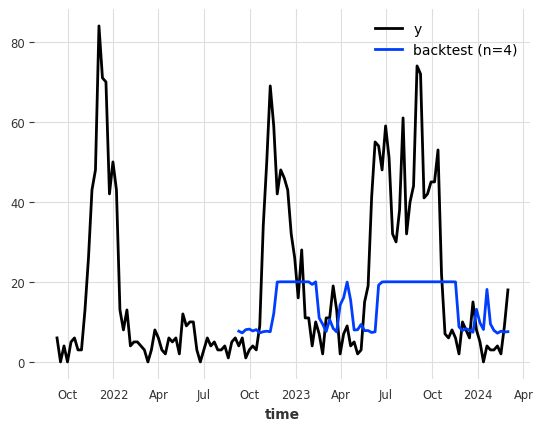

In [31]:
eval_model(
    brnn_no_cov,
    y_train,
    test_size=0.2,
    forecast_horizon=FORECAST_HORIZON
)

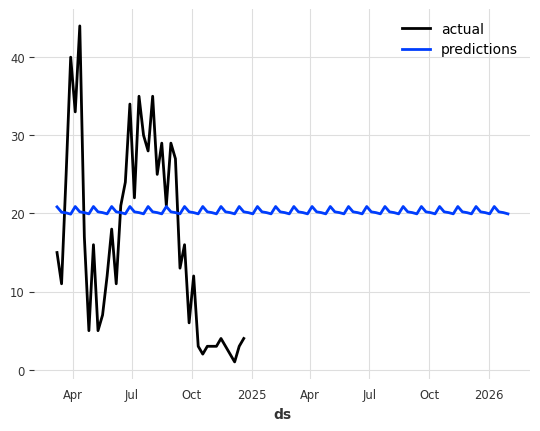

In [77]:
y_test.plot(label="actual")
preds_brnn_no_cov.plot(label="predictions")
plt.legend()

## With past covariates

In [66]:
brnn_past_cov = BlockRNNModel(
    input_chunk_length=52,
    output_chunk_length=FORECAST_HORIZON,
    n_rnn_layers=2,
)

In [67]:
brnn_past_cov.fit(
    y_train,
    past_covariates=X_train,
    epochs=100,
    verbose=True
)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs

  | Name            | Type             | Params | Mode 
-------------------------------------------------------------
0 | criterion       | MSELoss          | 0      | train
1 | train_criterion | MSELoss          | 0      | train
2 | val_criterion   | MSELoss          | 0      | train
3 | train_metrics   | MetricCollection | 0      | train
4 | val_metrics     | MetricCollection | 0      | train
5 | rnn             | RNN              | 2.5 K  | train
6 | fc              | Sequential       | 104    | train
-------------------------------------------------------------
2.6 K     Trainable params
0         Non-trainable params
2.6 K     Total params
0.011     Total estimated model params size (MB)
8         Modules in train mode
0         Modules in eval mode


Training: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=100` reached.


BlockRNNModel(output_chunk_shift=0, model=RNN, hidden_dim=25, n_rnn_layers=2, hidden_fc_sizes=None, dropout=0.0, activation=ReLU, input_chunk_length=52, output_chunk_length=4)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Predicting: |          | 0/? [00:00<?, ?it/s]

Backtest RMSE = 18.530709895382795


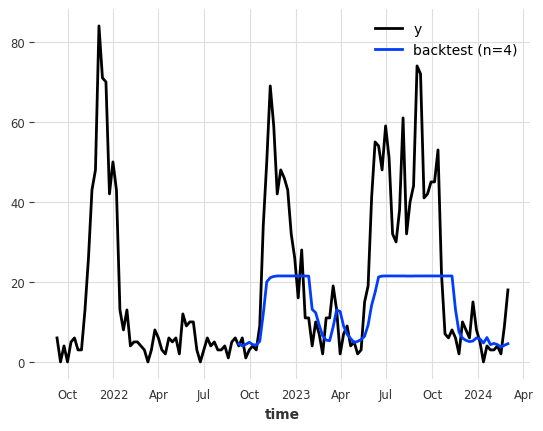

In [35]:
eval_model(
    brnn_past_cov,
    y_train,
    past_covariates=X_train,
    test_size=0.2,
    forecast_horizon=FORECAST_HORIZON
)

## Regression Model

In [63]:
regr_past_cov = RegressionModel(
    lags = 52,
    lags_past_covariates = [-8, -7, -6, -5, -4, -3, -2, -1],
)

In [64]:
regr_past_cov.fit(
    y_train,
    past_covariates=X_train
)

RegressionModel(lags=52, lags_past_covariates=[-8, -7, -6, -5, -4, -3, -2, -1], lags_future_covariates=None, output_chunk_length=1, output_chunk_shift=0, add_encoders=None, model=None, multi_models=True, use_static_covariates=True)

`enable_optimization=True` is ignored because `forecast_horizon > model.output_chunk_length`. To hide this warning, set `show_warnings=False` or `enable_optimization=False`.


historical forecasts:   0%|          | 0/78 [00:00<?, ?it/s]

`predict()` was called with `n > output_chunk_length`: using auto-regression to forecast the values after `output_chunk_length` points. The model will access `(n - output_chunk_length)` future values of your `past_covariates` (relative to the first predicted time step). To hide this warning, set `show_warnings=False`.


Backtest RMSE = 14.329061279221749


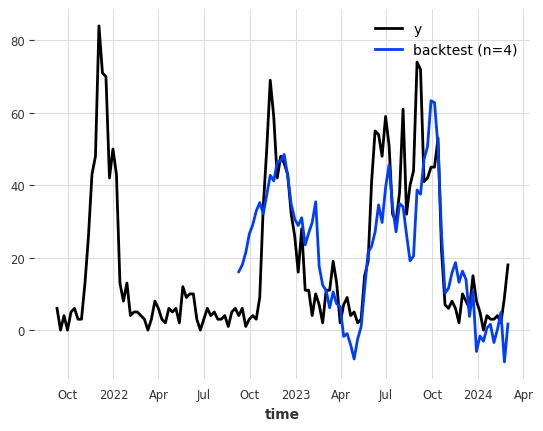

In [65]:
eval_model(
    regr_past_cov,
    y_train,
    past_covariates=X_train,
    test_size=0.2,
    forecast_horizon=FORECAST_HORIZON
)

In [ ]:
y_trainy_train.components.values

array(['y'], dtype=object)